# Calling Tool- Without MCP

In [13]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage

from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool
from langchain_ollama import ChatOllama
from langgraph.checkpoint.memory import MemorySaver
import requests

# -------------------
# 1. LLM
# -------------------
llm =ChatOllama(model="qwen3:4b")
#-----------------------------------------------------------------------------------------------------------------------
# -------------------
# 2. Tools
# -------------------
# Tools
search_tool = DuckDuckGoSearchRun(region="us-en")

@tool
def calculator(first_num: float, second_num: float, operation: str) -> dict:
    """
    Perform a basic arithmetic operation on two numbers.
    Supported operations: add, sub, mul, div
    """
    try:
        if operation == "add":
            result = first_num + second_num
        elif operation == "sub":
            result = first_num - second_num
        elif operation == "mul":
            result = first_num * second_num
        elif operation == "div":
            if second_num == 0:
                return {"error": "Division by zero is not allowed"}
            result = first_num / second_num
        else:
            return {"error": f"Unsupported operation '{operation}'"}
        
        return {"first_num": first_num, "second_num": second_num, "operation": operation, "result": result}
    except Exception as e:
        return {"error": str(e)}




@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA') 
    using Alpha Vantage with API key in the URL.
    """
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=C9PE94QUEW9VWGFM"
    r = requests.get(url)
    return r.json()



tools = [search_tool, get_stock_price, calculator]
llm_with_tools = llm.bind_tools(tools)
#-----------------------------------------------------------------------------------------------------------------------
# -------------------
# 3. State
# -------------------
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    
def build_graph():
   # -------------------
   # 4. Nodes
   # -------------------
   def chat_node(state: ChatState):
       """LLM node that may answer or request a tool call."""
       messages = state["messages"]
       response = llm_with_tools.invoke(messages)
       return {"messages": [response]}

   tool_node = ToolNode(tools)

   # -------------------
   # 6. Graph
   # -------------------
   graph = StateGraph(ChatState)
   graph.add_node("chat_node", chat_node)
   graph.add_node("tools", tool_node)

   graph.add_edge(START, "chat_node")
   graph.add_conditional_edges("chat_node",tools_condition)
   graph.add_edge('tools', 'chat_node')

   #create checkpoint for data saving
   checkpointer = MemorySaver()
   chatbot = graph.compile(checkpointer=checkpointer)
   return chatbot

def main():
  chatbot=build_graph()
  #define thread
  thread_id='1'
  while True:
    user_message=input('Type here : ')
    print('User :',user_message)
    if user_message.strip().lower() in ['exit','quit','bye']:
       break   

    config= {'configurable' :{'thread_id':thread_id}}
    response=chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
    print('AI :' ,response['messages'][-1].content)

if __name__ == '__main__':
    main()

/opt/anaconda3/lib/python3.13/ast.py:50: RuntimeWarning: coroutine 'main' was never awaited
  return compile(source, filename, mode, flags,


Type here :  hi


User : hi
AI : Hello! How can I assist you today? 😊


Type here :  stock price of apple


User : stock price of apple
AI : The current stock price for Apple (AAPL) is **$340.97** as of the latest trading day (2026-10-12), showing a **+1.29% increase** from the previous close. 📈


Type here :  bye


User : bye


# Convert into asynchronous operations
### Changes Required in the Code

1. Replace `def` with `async def` for functions that need to perform asynchronous operations.
2. Replace `invoke()` with `await ainvoke()` to call LangGraph asynchronously.
3. Call the main function using either:
   - `await main()` — in Jupyter Notebook or an environment with an active event loop.
   - `asyncio.run(main())` — in a regular Python script.


In [16]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage

from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool
from langchain_ollama import ChatOllama
from langgraph.checkpoint.memory import MemorySaver
import requests
import asyncio
# -------------------
# 1. LLM
# -------------------
llm =ChatOllama(model="qwen3:4b")
#-----------------------------------------------------------------------------------------------------------------------
# -------------------
# 2. Tools
# -------------------
# Tools
search_tool = DuckDuckGoSearchRun(region="us-en")

@tool
def calculator(first_num: float, second_num: float, operation: str) -> dict:
    """
    Perform a basic arithmetic operation on two numbers.
    Supported operations: add, sub, mul, div
    """
    try:
        if operation == "add":
            result = first_num + second_num
        elif operation == "sub":
            result = first_num - second_num
        elif operation == "mul":
            result = first_num * second_num
        elif operation == "div":
            if second_num == 0:
                return {"error": "Division by zero is not allowed"}
            result = first_num / second_num
        else:
            return {"error": f"Unsupported operation '{operation}'"}
        
        return {"first_num": first_num, "second_num": second_num, "operation": operation, "result": result}
    except Exception as e:
        return {"error": str(e)}




@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA') 
    using Alpha Vantage with API key in the URL.
    """
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=C9PE94QUEW9VWGFM"
    r = requests.get(url)
    return r.json()



tools = [search_tool, get_stock_price, calculator]
llm_with_tools = llm.bind_tools(tools)
#-----------------------------------------------------------------------------------------------------------------------
# -------------------
# 3. State
# -------------------
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    
async def build_graph():
   # -------------------
   # 4. Nodes
   # -------------------
   async def chat_node(state: ChatState):
       """LLM node that may answer or request a tool call."""
       messages = state["messages"]
       response = await llm_with_tools.ainvoke(messages)
       return {"messages": [response]}

   tool_node = ToolNode(tools)

   # -------------------
   # 6. Graph
   # -------------------
   graph = StateGraph(ChatState)
   graph.add_node("chat_node", chat_node)
   graph.add_node("tools", tool_node)

   graph.add_edge(START, "chat_node")
   graph.add_conditional_edges("chat_node",tools_condition)
   graph.add_edge('tools', 'chat_node')

   #create checkpoint for data saving
   checkpointer = MemorySaver()
   chatbot = graph.compile(checkpointer=checkpointer)
   return chatbot

async def main():
  #chatbot=build_graph()
  chatbot= await build_graph()
  #define thread
  thread_id='1'
  while True:
    user_message=input('Type here : ')
    print('User :',user_message)
    if user_message.strip().lower() in ['exit','quit','bye']:
       break   

    config= {'configurable' :{'thread_id':thread_id}}
    #response=chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
    response=await chatbot.ainvoke({'messages':[HumanMessage(content=user_message)]},config=config)
    print('AI :' ,response['messages'][-1].content)

if __name__ == '__main__':
 #   main()
 # asyncio.run(main()) for terminal
 await main()

Type here :  hi


User : hi
AI : Hello! How can I assist you today? 😊


Type here :  stock price of apple


User : stock price of apple
AI : The latest stock price for Apple (AAPL) as of **2026-10-12** is **$340.97**, up **$4.33** (1.29%) from the previous close. 

Let me know if you'd like further details! 😊


Type here :  bye


User : bye


# Calling Tool-MCP

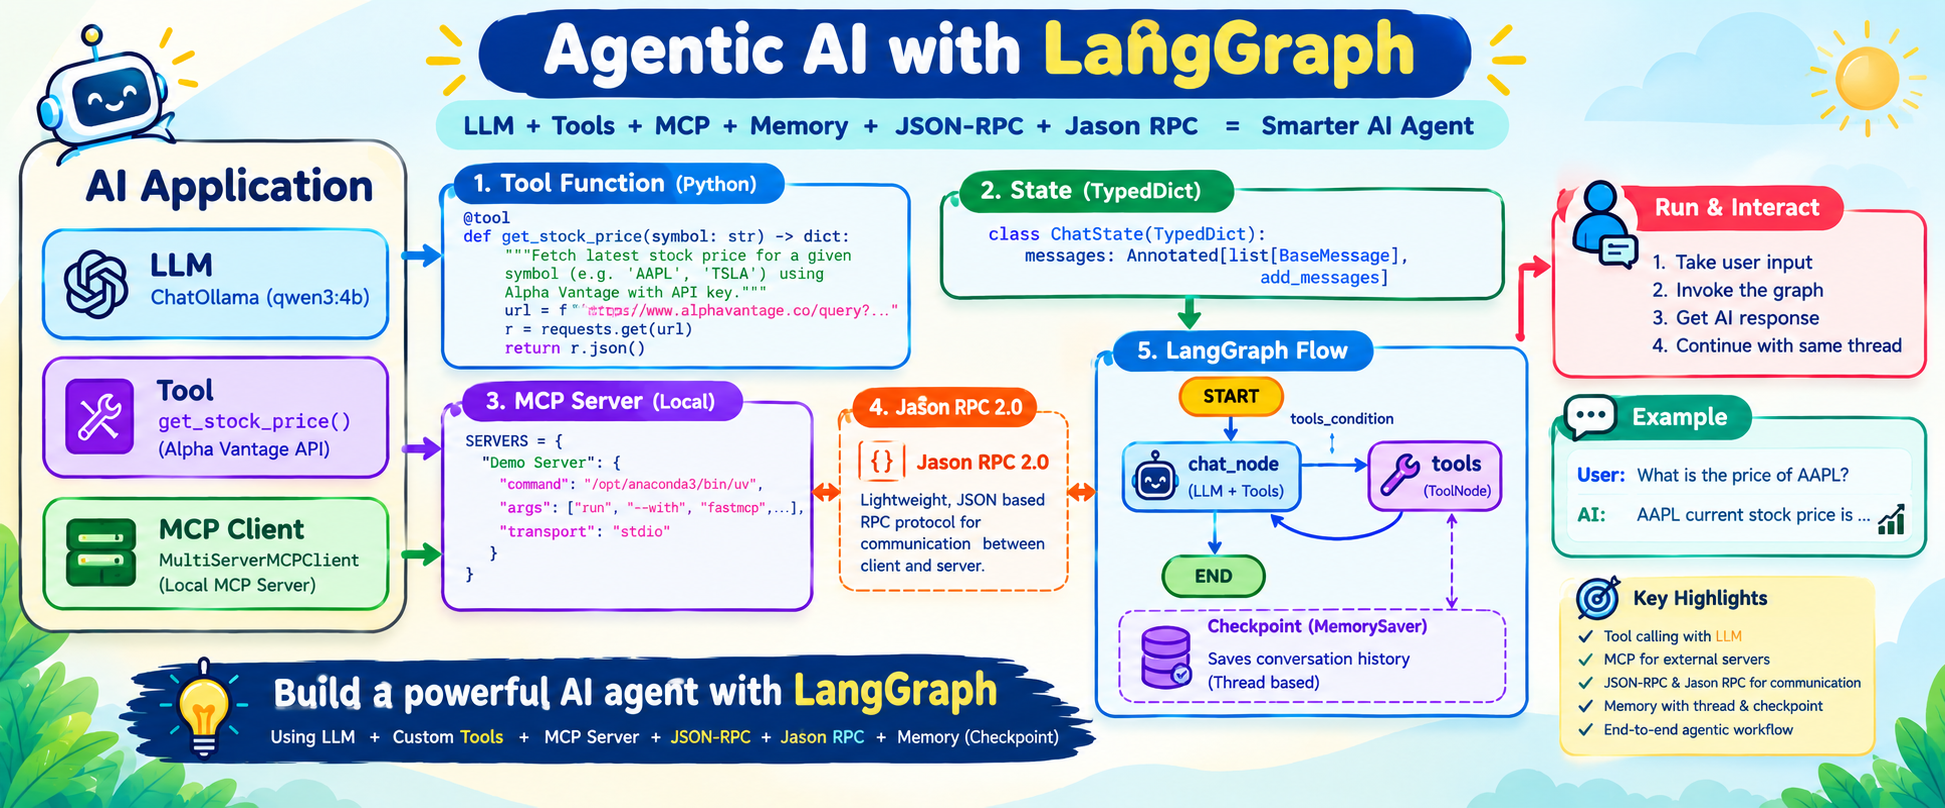

In [33]:
from IPython.display import Image, display
display(Image(filename="image/MCPFLOWchatbot.png", width=800))

In [32]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage

from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool
from langchain_ollama import ChatOllama
from langgraph.checkpoint.memory import MemorySaver
import requests
import asyncio
from langchain_mcp_adapters.client import MultiServerMCPClient
# -------------------
# 1. LLM
# -------------------
llm =ChatOllama(model="qwen3:4b")
#-----------------------------------------------------------------------------------------------------------------------
# -------------------
# 2. Tools
# -------------------
# Tools
@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA') 
    using Alpha Vantage with API key in the URL.
    """
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=C9PE94QUEW9VWGFM"
    r = requests.get(url)
    return r.json()
    
SERVERS = {
    #Local Server
    "Demo Server": {
      "command": "/opt/anaconda3/bin/uv",
      "args": [
        "run",
        "--with",
        "fastmcp",
        "fastmcp",
        "run",
        "/Users/shashi/Desktop/MCP Demo/main.py"
      ],
      "env": {},
      "transport": "stdio"
    }
    #Remove server
    # "Remote": {
        # "transport": "streamable_http",
        # "url": "https://shashi-demo-remote-server.fastmcp.app/mcp",
    # }
}

client = MultiServerMCPClient(SERVERS)

#-----------------------------------------------------------------------------------------------------------------------
# -------------------
# 3. State
# -------------------
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    
async def build_graph():
    
   mcp_tools = await client.get_tools()
   tools=[get_stock_price, *mcp_tools]
   print("Tools: ",[tool.name for tool in tools])
   llm_with_tools = llm.bind_tools(tools)
   # -------------------
   # 4. Nodes
   # -------------------
   async def chat_node(state: ChatState):
       """LLM node that may answer or request a tool call."""
       messages = state["messages"]
       response = await llm_with_tools.ainvoke(messages)
       return {"messages": [response]}

   tool_node = ToolNode(tools)

   # -------------------
   # 6. Graph
   # -------------------
   graph = StateGraph(ChatState)
   graph.add_node("chat_node", chat_node)
   graph.add_node("tools", tool_node)

   graph.add_edge(START, "chat_node")
   graph.add_conditional_edges("chat_node",tools_condition)
   graph.add_edge('tools', 'chat_node')

   #create checkpoint for data saving
   checkpointer = MemorySaver()
   chatbot = graph.compile(checkpointer=checkpointer)
   return chatbot

async def main():
  #chatbot=build_graph()
  chatbot= await build_graph()
  #define thread
  thread_id='1'
  while True:
    user_message=input('Type here : ')
    print('User :',user_message)
    if user_message.strip().lower() in ['exit','quit','bye']:
       break   

    config= {'configurable' :{'thread_id':thread_id}}
    #response=chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
    response=await chatbot.ainvoke({'messages':[HumanMessage(content=user_message)]},config=config)
    print('AI :' ,response['messages'][-1].content)

if __name__ == '__main__':
 #   main()
 # asyncio.run(main()) for terminal
 await main()

Tools:  ['get_stock_price', 'roll_dice', 'add_numbers']


Type here :  hi


User : hi
AI : Hello! How can I assist you today? 😊


Type here :  apple stock price


User : apple stock price
AI : The latest stock price for Apple (AAPL) is **$340.97** as of today. It's up **$4.33 (1.29%)** from the previous close. 😊


Type here :  roll dice


User : roll dice
AI : You rolled a **1**! 🎲


Type here :  bye


User : bye


# Complete Step-by-Step Explanation of LangGraph MCP Chatbot

## 1. Introduction

This program creates an Agentic AI chatbot using LangGraph, Ollama, MCP tools, asynchronous programming, and checkpoint-based memory.

The chatbot uses three tools:

1. `get_stock_price` — retrieves stock quote data from Alpha Vantage.
2. `roll_dice` — rolls one or more six-sided dice using an MCP tool.
3. `add_numbers` — adds two numbers using an MCP tool.

The chatbot can understand user requests, select appropriate tools, execute tool calls, process tool results, and maintain conversation state within a thread.

## 2. Import Required Libraries

```python
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.tools import tool
from langchain_ollama import ChatOllama
from langgraph.checkpoint.memory import MemorySaverimport requestsimport asyncio
from langchain_mcp_adapters.client import MultiServerMCPClient
```

Explanation:

- `StateGraph` — creates the LangGraph workflow.
- `START` — defines the starting point of the graph.
- `END` — represents the end of the graph; it is not explicitly used in this code.
- `TypedDict` — defines the expected structure of the graph state.
- `Annotated` — attaches metadata to a type declaration.
- `BaseMessage` — base class for LangChain messages.
- `HumanMessage` — represents a user message.
- `add_messages` — merges new messages into the existing message history.
- `ToolNode` — executes tools requested by the LLM.
- `tools_condition` — routes execution based on whether the AI message contains a tool call.
- `tool` — converts a Python function into a LangChain tool.
- `ChatOllama` — connects to a model running through Ollama.
- `MemorySaver` — saves graph checkpoints in application memory.
- `requests` — sends synchronous HTTP requests.
- `asyncio` — manages asynchronous execution.
- `MultiServerMCPClient` — discovers and invokes tools exposed by configured MCP servers.

## 3. Initialize the LLM

```
llm = ChatOllama(model="qwen3:4b")
```

Explanation:

1. `ChatOllama` creates an interface to the Ollama model.
2. `model="qwen3:4b"` selects the Qwen3 model with approximately four billion parameters.
3. The model generates responses based on conversation messages.
4. Later, `bind_tools()` makes the available tools accessible to the model.

Important: The LLM can request a tool call, but it does not execute your Python tools directly. LangGraph's `ToolNode` handles execution.

## 4. Create a Custom Stock-Price Tool

```python
@tooldef 
get_stock_price(symbol: str) -> dict:    
   """Fetch stock quote data for a given symbol."""   
   url = ("https://www.alphavantage.co/query"f"?function=GLOBAL_QUOTE&symbol={symbol}""&apikey=YOUR_API_KEY")
   r = requests.get(url)    
   return r.json()
```

Explanation:

1. `@tool` registers the function as a LangChain tool.
2. `get_stock_price` is the tool name.
3. `symbol: str` specifies that the input should be a string, such as `AAPL` or `TSLA`.
4. `dict` indicates the expected return type.
5. The URL requests data from Alpha Vantage's `GLOBAL_QUOTE` endpoint.
6. `requests.get(url)` sends an HTTP request.
7. `r.json()` converts the API response into a Python dictionary.

Example user request:

```
What is the stock price of AAPL?
```

The LLM may request a call equivalent to:

```
get_stock_price(symbol="AAPL")
```

The tool returns the API response, which the LLM can use to formulate an answer.

Security and reliability: Store your API key in an environment variable, rotate the key previously hardcoded in the code, and add HTTP timeouts, error handling, and response validation. The API may return rate-limit messages or missing quote data instead of a price.

## 5. Configure the MCP Server

```python
SERVERS = {
    #Local Server
    "Demo Server": {
      "command": "/opt/anaconda3/bin/uv",
      "args": [
        "run",
        "--with",
        "fastmcp",
        "fastmcp",
        "run",
        "/Users/shashi/Desktop/MCP Demo/main.py"
      ],
      "env": {},
      "transport": "stdio"
    }
    #Remove server
    # "Remote": {
        # "transport": "streamable_http",
        # "url": "https://shashi-demo-remote-server.fastmcp.app/mcp",
    # }
}
```

Explanation:

- `SERVERS` defines the MCP server configurations.
- `"Demo Server"` is the configuration name.
- `command` specifies the executable used to start the server.
- `args` contains the command-line arguments for launching the FastMCP server.
- `env` provides additional environment variables, if required.
- `transport: "stdio"` specifies communication through standard input and standard output.

The configuration tells the MCP client how to launch and communicate with your local MCP server.

Your server exposes these tools:

```
roll_dice
add_numbers
```

## 6. Create the MCP Client

```
client = MultiServerMCPClient(SERVERS)
```

Explanation:

1. `MultiServerMCPClient` creates a client using the server configuration.
2. `SERVERS` identifies the MCP server to connect to.
3. The client provides methods to discover and invoke MCP tools.
4. Later, `client.get_tools()` retrieves the tools exposed by the server.

The MCP client acts as the connection between the LangGraph application and the MCP server.

## 7. Understand `async`, `await`, and Asynchronous Programming

### 7.1 What is `async`?

`async` is a Python keyword used to define an asynchronous function.

```
async def build_graph():    ...
```

Explanation:

1. `async def` defines a coroutine function.
2. Calling the function normally creates a coroutine object.
3. The coroutine must be awaited or run by an event loop to execute to completion.
4. Asynchronous functions are useful for operations that spend time waiting for I/O, such as network requests and LLM responses.

Example:

```
result = await build_graph()
```

Here, the caller waits for the asynchronous function to finish and receive its result.

### 7.2 What is `await`?

`await` waits for an awaitable operation to complete before continuing that part of the function.

```
mcp_tools = await client.get_tools()
```

Execution steps:

1. `client.get_tools()` initiates the asynchronous tool-discovery operation.
2. `await` suspends the current coroutine while the operation is pending.
3. The event loop can run other eligible tasks during that wait.
4. When discovery completes, the returned tools are assigned to `mcp_tools`.
5. The function continues with the next statement.

`await` does not automatically make a synchronous operation asynchronous. The operation being awaited must support asynchronous execution.

### 7.3 What is an event loop?

An event loop schedules asynchronous tasks and resumes them when their awaited operations are ready.

In your chatbot, it manages asynchronous operations such as:

- Waiting for the LLM to respond.
- Waiting for MCP tool discovery.
- Waiting for asynchronous graph execution.

### 7.4 Difference between `async` and `await`

| Concept         | Purpose                                         |
| --------------- | ----------------------------------------------- |
| `async def`     | Defines a coroutine function.                   |
| `await`         | Waits for an awaitable operation to finish.     |
| Event loop      | Schedules and manages asynchronous tasks.       |
| `asyncio.run()` | Runs a top-level coroutine using an event loop. |

## 8. Define the Chatbot State

```
class ChatState(TypedDict):    messages: Annotated[list[BaseMessage], add_messages]
```

Explanation:

- `ChatState` defines the structure of the state passed between graph nodes.
- `TypedDict` specifies the expected dictionary structure.
- `messages` stores the conversation history.
- `BaseMessage` is the base type for human, AI, and tool messages.
- `Annotated` attaches metadata to the message-list type.
- `add_messages` tells LangGraph to merge new messages into the existing message history.

Example state:

```python
{"messages": [HumanMessage(content="My name is Shashi")]}
```

When the graph returns new messages, `add_messages` updates the message history instead of simply replacing it with the latest message.

## 9. Retrieve MCP Tools

```
mcp_tools = await client.get_tools()
```

Explanation:

1. The MCP client discovers the tools exposed by the configured server.
2. `await` waits for the asynchronous discovery operation.
3. The returned tool objects are stored in `mcp_tools`.

Expected tool names:

```
roll_dice
add_numbers
```

To print only the names:

```
print([t.name for t in mcp_tools])
```

Output:

```
['roll_dice', 'add_numbers']
```

## 10. Combine Custom and MCP Tools

```
tools = [get_stock_price, *mcp_tools]
```

Explanation:

1. `get_stock_price` is your custom LangChain tool.
2. `*mcp_tools` unpacks the MCP tool list.
3. The resulting list contains all three tools.

Expected names:

```
get_stock_price
roll_dice
add_numbers
```

You can verify them with:

```
print([t.name for t in tools])
```

## 11. Bind Tools to the LLM

```
llm_with_tools = llm.bind_tools(tools)
```

Explanation:

1. `llm.bind_tools(tools)` makes the tool definitions available to the model.
2. The model can inspect the tool names, descriptions, and input schemas.
3. Based on the user's request, the model can generate a tool-call request.
4. The tool call is returned as part of an AI message.
5. `ToolNode` executes the requested tool later.

Important: `bind_tools()` does not execute tools. It enables the LLM to request tool calls.

## 12. Create the Chat Node

```python
async def chat_node(state: ChatState):    
      messages = state["messages"]    
      response = await llm_with_tools.ainvoke(messages)    
      return {"messages": [response]}
```

Explanation:

1. `chat_node` is an asynchronous graph node.
2. `state["messages"]` retrieves the current conversation history.
3. `llm_with_tools.ainvoke(messages)` sends the message history to the LLM asynchronously.
4. `await` waits for the model response.
5. `response` contains an AI message with either ordinary text or a tool-call request.
6. `return {"messages": [response]}` sends the new message back to LangGraph for merging into the state.

The chat node is responsible for the LLM's decision. It does not execute tools directly.

## 13. Understand `invoke()` and `ainvoke()`

### Synchronous execution using `invoke()`

```python
response = chatbot.invoke({"messages": [HumanMessage(content="Hello")]})
```

- Executes the graph synchronously.
- Returns the completed graph state.
- Blocks the calling code until execution finishes.

### Asynchronous execution using `ainvoke()`

```python
response = await chatbot.ainvoke({"messages": [HumanMessage(content="Hello")]})
```

- Executes the graph using its asynchronous interface.
- Returns an awaitable result.
- `await` waits for graph execution to finish and provides the completed state.

| Method      | Purpose                        |
| ----------- | ------------------------------ |
| `invoke()`  | Synchronous graph execution.   |
| `ainvoke()` | Asynchronous graph execution.  |
| `await`     | Waits for an awaitable result. |

Remember: `ainvoke()` requests asynchronous graph execution; `await` waits for that execution to complete.

## 14. Create the Tool Node

```python
tool_node = ToolNode(tools)
```

Explanation:

1. `ToolNode` receives the combined tool list.
2. It inspects tool calls requested by the AI message.
3. It invokes the corresponding tool.
4. It collects the result and returns tool messages to the graph state.

For example, if the LLM requests:

```python
add_numbers(a=10, b=20)
```

`ToolNode` executes the tool and returns its result.

The same node can execute `get_stock_price`, `roll_dice`, or `add_numbers`.

Important: Your `ToolNode` must receive the same combined tool list that you passed to `llm.bind_tools(tools)`. Your current code does this correctly.

## 15. Create the LangGraph Workflow

```python
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)
```

Explanation:

- `StateGraph(ChatState)` creates the graph using `ChatState` as its state schema.
- `add_node("chat_node", chat_node)` registers the LLM node.
- `add_node("tools", tool_node)` registers the tool-execution node.

At this point, the nodes are registered. Edges are required to define their execution order.

## 16. Define Graph Edges and Conditional Routing

```python
graph.add_edge(START, "chat_node")
graph.add_conditional_edges("chat_node",tools_condition)
graph.add_edge("tools", "chat_node")
```

### Edge 1 — Start the graph

```python
graph.add_edge(START, "chat_node")
```

Every new graph invocation begins at `chat_node`.

### Edge 2 — Decide whether to call a tool

```python
graph.add_conditional_edges("chat_node",tools_condition)
```

`tools_condition` examines the latest AI message:

- If the AI message contains a tool call, execution moves to `tools`.
- If there is no tool call, execution moves to the graph's end.

### Edge 3 — Return to the LLM

```python
graph.add_edge("tools", "chat_node")
```

After a tool executes:

1. The tool result is added to the message history.
2. Execution returns to `chat_node`.
3. The LLM processes the result.
4. The LLM can answer the user or request another tool.

The graph continues until the LLM produces a response without a tool call.

## 17. Enable Checkpointing

```python
checkpointer = MemorySaver()
chatbot = graph.compile(checkpointer=checkpointer)
return chatbot
```

Explanation:

- `MemorySaver()` creates an in-memory checkpointer.
- `graph.compile()` prepares the graph for execution and configures checkpointing.
- `chatbot` is the compiled graph.
- `return chatbot` sends the compiled graph back to the calling function.

### What is checkpointing?

Checkpointing saves graph state at execution checkpoints so that a conversation can resume from its previously saved state.

### What is a thread ID?

```python
thread_id = "1"
config = { "configurable": { "thread_id": thread_id}}
```

The thread ID identifies which conversation state to resume.

Example:

1. User enters: `My name is Shashi`.
2. The graph processes the message and saves its state.
3. User enters: `What is my name?`.
4. The second invocation uses the same thread ID.
5. The LLM can use the earlier message to answer.

Limitation: `MemorySaver` stores state in application memory. Checkpoints are normally lost when the process ends. Use a persistent checkpointer such as SQLite to preserve state across restarts.

## 18. Create the Main Function

```python
async def main():
  #chatbot=build_graph()
  chatbot= await build_graph()
  #define thread
  thread_id='1'
  while True:
    user_message=input('Type here : ')
    print('User :',user_message)
    if user_message.strip().lower() in ['exit','quit','bye']:
       break   

    config= {'configurable' :{'thread_id':thread_id}}
    #response=chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
    response=await chatbot.ainvoke({'messages':[HumanMessage(content=user_message)]},config=config)
    print('AI :' ,response['messages'][-1].content)
```

Step-by-step explanation:

1. `async def main()` defines the main asynchronous function.
2. `await build_graph()` builds the graph and waits for the compiled chatbot.
3. `thread_id = "1"` selects the conversation thread.
4. `while True` starts a loop that continues until the user exits.
5. `input()` receives the user's terminal message.
6. The `if` condition checks for `exit`, `quit`, or `bye`.
7. `config` identifies the checkpointed conversation thread.
8. `HumanMessage(content=user_message)` converts the input into a LangChain human message.
9. `await chatbot.ainvoke(...)` runs the graph asynchronously.
10. `response["messages"][-1]` selects the final message in the returned state.
11. `.content` extracts the message content.
12. `print()` displays the answer.

Note: `input()` is synchronous and blocks while waiting for terminal input. This is acceptable for a simple command-line chatbot, but it is not a fully asynchronous input mechanism.

## 19. Run the Program

Use this entry point in a regular Python script:

```python
if __name__ == "__main__":    
   asyncio.run(main())
```

Explanation:

1. `if __name__ == "__main__":` checks whether the file is being run directly.
2. `asyncio.run(main())` creates and manages an event loop.
3. The event loop executes the `main()` coroutine.
4. The program runs until `main()` completes.
5. The event loop is then closed.

Do not use top-level `await main()` in a regular `.py` script. In notebook environments that already support top-level `await`, you can generally use `await main()` directly in a notebook cell.

## 20. Complete Tool-Calling Example

Suppose the user enters:

```python
Add 10 and 20
```

The execution sequence is:

1. The terminal receives the input.
2. The program converts it into a `HumanMessage`.
3. The message is passed to the compiled graph.
4. `chat_node` sends the conversation history to Qwen3:4b.
5. The LLM requests the `add_numbers` tool.
6. `tools_condition` routes execution to `ToolNode`.
7. `ToolNode` executes the MCP tool.
8. The tool returns `30`.
9. The tool result is added to the graph's message history.
10. Execution returns to `chat_node`.
11. The LLM uses the tool result to generate the final answer.
12. Because no additional tool call is requested, the graph ends.
13. The program prints the final response.
14. The checkpointed state is associated with thread `"1"`.

The final answer might be:

```
AI: The result of adding 10 and 20 is 30.
```

The exact wording depends on the LLM.

## 21. Important Technical Considerations

- Stock-price HTTP requests: `requests.get()` is synchronous. It can block the event loop while waiting for the API. Consider `httpx.AsyncClient` for asynchronous HTTP calls.
- API key security: Store the Alpha Vantage key in an environment variable and rotate the key previously hardcoded in your code.
- API error handling: Add timeouts, HTTP error checks, and validation for missing quotes or rate-limit messages.
- Checkpoint persistence: `MemorySaver` does not provide durable storage across process restarts.
- Model support: Tool calling depends on the Ollama model and version. Verify that your installed model supports the expected tool-calling behavior.
- Unused imports: Remove `DuckDuckGoSearchRun` and `END` if you do not use them elsewhere.

## 22. Final Summary

| Component         | Responsibility                                          |
| ----------------- | ------------------------------------------------------- |
| Qwen3:4b          | Understands requests and decides whether to call tools. |
| `get_stock_price` | Retrieves stock quote data.                             |
| MCP client        | Discovers and invokes MCP tools.                        |
| `bind_tools()`    | Makes tool definitions available to the LLM.            |
| `ChatState`       | Stores the conversation message history.                |
| `chat_node`       | Invokes the LLM.                                        |
| `ToolNode`        | Executes requested tools.                               |
| `tools_condition` | Routes execution based on tool calls.                   |
| `StateGraph`      | Defines the agent workflow.                             |
| `MemorySaver`     | Saves checkpointed state in memory.                     |
| `thread_id`       | Identifies the conversation state.                      |
| `async`           | Defines asynchronous functions.                         |
| `await`           | Waits for asynchronous operations.                      |
| `ainvoke()`       | Runs the graph asynchronously.                          |
| `asyncio.run()`   | Starts the main coroutine in a regular Python script.   |

Overall program flow: User input → ChatState → LLM decision → conditional tool execution → tool result → LLM response → checkpointed conversation state → terminal output.